# Boundary Conformance Replay
Recompute a bounded normalization-boundary study from **two saved native
acquisitions**. CPU, internet off, no credentials, downloads or installs.
This is saved-trace numerical replay, not fresh framework execution,
learned inference, hardware calibration or a population accuracy estimate.

Three dependency-linked metadata groups supply four cells; the OpenPI
cell transports the same PI statistics. Sixteen actual conditions and
eight derived views reuse observations. See the dataset card for the
source/license inventory, prior inspection and experimental limits.


In [1]:
def prepare_payload(input_root, destination, archive_sha256, manifest_sha256):
    # This complete function is embedded verbatim into the generated notebook.
    import hashlib
    import json
    import stat
    import zipfile
    from pathlib import Path, PurePosixPath

    def digest(raw):
        return hashlib.sha256(raw).hexdigest()

    def safe(name):
        p = PurePosixPath(name)
        assert name and "\\" not in name and not p.is_absolute(), "Unsafe payload path"
        assert p.as_posix() == name and all(x not in ("", ".", "..") and ":" not in x for x in p.parts)
        return p

    input_root, destination = Path(input_root), Path(destination)
    assert not destination.exists(), "Use a new payload destination"
    archives = [
        p for p in sorted(input_root.rglob("payload.zip")) if digest(p.read_bytes()) == archive_sha256
    ]
    if archives:
        assert len(archives) == 1, "Attach only one matching dataset version"
        with zipfile.ZipFile(archives[0]) as archive:
            entries = archive.infolist()
            assert 0 < len(entries) <= 2000
            assert sum(i.file_size for i in entries) <= 64 * 1024 * 1024
            assert len({i.filename.casefold() for i in entries}) == len(entries)
            for item in entries:
                safe(item.filename)
                assert not item.is_dir() and stat.S_IFMT(item.external_attr >> 16) in (0, stat.S_IFREG)
                assert not item.flag_bits & 1
            for item in entries:
                path = destination.joinpath(*safe(item.filename).parts)
                path.parent.mkdir(parents=True, exist_ok=True)
                path.write_bytes(archive.read(item))
        representation = "archive"
    else:
        candidates = [
            p for p in sorted(input_root.rglob("manifest.json")) if digest(p.read_bytes()) == manifest_sha256
        ]
        assert len(candidates) == 1, "Attach the dataset version with the pinned payload manifest"
        source = candidates[0].parent
        manifest = json.loads(candidates[0].read_bytes())
        expected = manifest["files"]
        assert 0 < len(expected) < 2000 and manifest["schema_version"] == 1
        paths = list(source.rglob("*"))
        assert not any(p.is_symlink() for p in paths), "No payload symlinks"
        assert {p.relative_to(source).as_posix() for p in paths if p.is_file()} == set(expected) | {
            "manifest.json"
        }
        assert sum(p.stat().st_size for p in paths if p.is_file()) <= 64 * 1024 * 1024
        # Check bytes before copying or importing any payload source.
        for name, expected_sha in expected.items():
            path = source.joinpath(*safe(name).parts)
            assert digest(path.read_bytes()) == expected_sha, "Expanded payload hash mismatch: " + name
        for name in [*expected, "manifest.json"]:
            raw = source.joinpath(*safe(name).parts).read_bytes()
            path = destination.joinpath(*safe(name).parts)
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(raw)
        representation = "expanded-directory"
    assert digest((destination / "manifest.json").read_bytes()) == manifest_sha256
    manifest = json.loads((destination / "manifest.json").read_bytes())
    expected = manifest["files"]
    assert {p.relative_to(destination).as_posix() for p in destination.rglob("*") if p.is_file()} == (
        set(expected) | {"manifest.json"}
    )
    for name, expected_sha in expected.items():
        assert digest(destination.joinpath(*safe(name).parts).read_bytes()) == expected_sha
    return representation


import hashlib, json, os, shutil, subprocess, sys, tempfile
from pathlib import Path
PAYLOAD_SHA256 = 'acf9a8cdafb049b36603bd0ef159c419d361ca000f8cca9c5d100468aa9dc14f'
PAYLOAD_MANIFEST_SHA256 = 'ee5c8eeea0cbb6c7522f774e6012149d73fa11fa06d635b7e440b2086eb9cfaf'
RELEASE_ID = '0e8e23615dc6e9aa19023cb58a70eacf6095b32da8b8fa4f57e79c0f3c1d02a6'
# The override is only for local smoke tests; Kaggle uses the attached dataset.
input_root = Path(os.environ.get("MLTOOLS_INPUT", "/kaggle/input"))
working = Path(os.environ.get("MLTOOLS_OUTPUT", "/kaggle/working"))
working.mkdir(parents=True, exist_ok=True)
expected_names = {"analysis.json", "metrics.json", "witnesses.json", "workflow-analysis.json",
                   "conditions.csv", "replay-summary.json", "replay-report.json", "outcomes.svg"}
assert not any((working / n).exists() for n in expected_names), "Use a clean output directory"
scratch = Path(tempfile.mkdtemp(prefix="mltools-replay-"))
unpacked = scratch / "payload"
representation = prepare_payload(input_root, unpacked, PAYLOAD_SHA256, PAYLOAD_MANIFEST_SHA256)
print("Pinned release:", RELEASE_ID)
print("Verified input representation:", representation)


Pinned release: 0e8e23615dc6e9aa19023cb58a70eacf6095b32da8b8fa4f57e79c0f3c1d02a6
Verified input representation: expanded-directory


Kaggle expands uploaded ZIPs. The notebook verifies the pinned archive
hash when a ZIP is present, or the pinned manifest hash and every member
hash when Kaggle supplies the expanded directory. The payload SHA256
identifies the original upload; it is not a claim to have downloaded a
ZIP when only expanded files are present. The replay
subprocess verifies every released file, revalidates saved native input/
output relations, reconstructs all five products, checks each against
its saved product and compares both acquisitions. Original Git/native
verification was performed by the builder before export. Neither this
notebook nor a producer hash independently attests the original runtime.


In [2]:
# A fresh isolated process prevents notebook preloaded libraries from
# contaminating the stdlib-only replay. The audit hook denies network.
runner = """import runpy, sys
def audit(event, args):
    if event in ('socket.connect', 'socket.connect_ex', 'socket.getaddrinfo', 'socket.bind'):
        raise RuntimeError('offline replay: network forbidden')
sys.addaudithook(audit)
sys.dont_write_bytecode = True
sys.path.insert(0, sys.argv[1])
sys.argv = [sys.argv[1] + '/replay.py', '--output', sys.argv[2]]
runpy.run_path(sys.argv[0], run_name='__main__')
"""
try:
    result = subprocess.run([sys.executable, "-I", "-S", "-B", "-c", runner,
                             str(unpacked), str(scratch / "results")],
                            check=True, capture_output=True, text=True, timeout=180)
    print(result.stdout)
    for file in (scratch / "results").iterdir():
        shutil.copyfile(file, working / file.name)
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise
finally:
    shutil.rmtree(scratch)
summary = json.loads((working / "replay-summary.json").read_bytes())
assert summary["status"] == "SAVED_TRACE_REPLAY_VERIFIED"
assert summary["release_id"] == RELEASE_ID
assert summary["compiled_fault_fail"] == 12 and summary["compiled_control_fail"] == 0
assert summary["counts"]["actual_conditions"] == 16 and summary["counts"]["derived_views"] == 8


{
  "schema_version": 1,
  "status": "SAVED_TRACE_REPLAY_VERIFIED",
  "release_id": "0e8e23615dc6e9aa19023cb58a70eacf6095b32da8b8fa4f57e79c0f3c1d02a6",
  "scope": "Two saved acquisitions reanalyzed; no fresh native execution or Git ancestry verification on Kaggle",
  "counts": {
    "execution_cells": 4,
    "artifact_groups": 3,
    "actual_conditions": 16,
    "derived_views": 8,
    "primary_decoder_calls": 1792,
    "auxiliary_native_calls": 896,
    "actual_shared_fresh_decoder_calls": 16,
    "policy_space_replay_queries": 1792,
    "policy_space_structural_controls": 16
  },
  "semantic_products_checked_per_run": 5,
  "compiled_fault_fail": 12,
  "compiled_control_fail": 0,
  "physical_unknown_rows": 24
}



## Inspect the finite results
With full numerical authority, all three methods detect 12/12 injected
changes, fail 0/4 controls and abstain on eight derived views. Every
physical-authority view is UNKNOWN. Candidate self-round trips remain
consistent for all sixteen actual conditions; they do not establish
independent-reference conformance. These are correlated finite cases.


In [3]:
import csv
from collections import Counter
rows = list(csv.DictReader((working / "conditions.csv").open(encoding="utf-8", newline="")))
assert len(rows) == 24 and Counter(r["physical"] for r in rows) == {"UNKNOWN": 24}
for method in ("compiled", "pointwise", "strong"):
    print(method, dict(Counter(r[method] for r in rows)))
metrics = json.loads((working / "metrics.json").read_bytes())
print("Original acquisition call accounting:", metrics["counts"])
analysis = json.loads((working / "analysis.json").read_bytes())
for cell, conditions in analysis["cells"].items():
    print(cell, "offset-authority ablation:")
    for condition, row in conditions.items():
        if "ablations" in row:
            view = row["ablations"]["offset_authority_erased"]
            print(" ", condition, view)


compiled {'PASS': 4, 'FAIL': 12, 'UNKNOWN': 8}
pointwise {'PASS': 4, 'FAIL': 12, 'UNKNOWN': 8}
strong {'PASS': 4, 'FAIL': 12, 'UNKNOWN': 8}
Original acquisition call accounting: {'execution_cells': 4, 'artifact_groups': 3, 'actual_conditions': 16, 'derived_views': 8, 'primary_decoder_calls': 1792, 'auxiliary_native_calls': 896, 'actual_shared_fresh_decoder_calls': 16, 'policy_space_replay_queries': 1792, 'policy_space_structural_controls': 16}
act_boccia_lerobot offset-authority ablation:
  numeric_control {'compiled': {'schema_version': 1, 'method': 'affine-obligations-development', 'status': 'UNKNOWN', 'suite_sha256': 'ae6dba512a65c2a500651347af421d54de012cbb18d972404b57846387f534a6', 'reference_sha256': 'e729a3ec370d5ef609ca5157477397609ebe6fc514c082a4b0b16ced5b1d0130', 'evidence_sha256': '84486f71d28a6b2310b558a2bc5ad2e50ede04ca1eadf624c310b369ca0d58db', 'coverage': {'rank_by_output': {'raw_action_0': 7, 'raw_action_1': 7, 'raw_action_2': 7, 'raw_action_3': 7, 'raw_action_4': 7, 'r

Removing only offset authority leaves slope evidence for compiled and
strong relational methods in eight changed cases; pointwise comparison
abstains. Full-reference parity excludes these ablations. All eight
equal-budget designs agree on reported finite/full-affine statuses.
Compiled witness method views total 16 calls, versus 12 each for the two
comparisons, with 16 shared acquired calls. No witness-size or detection
superiority is claimed. Robotruth's missing-evidence certification is
WITHHELD; structural Policy Space acceptance is not numerical conformance.


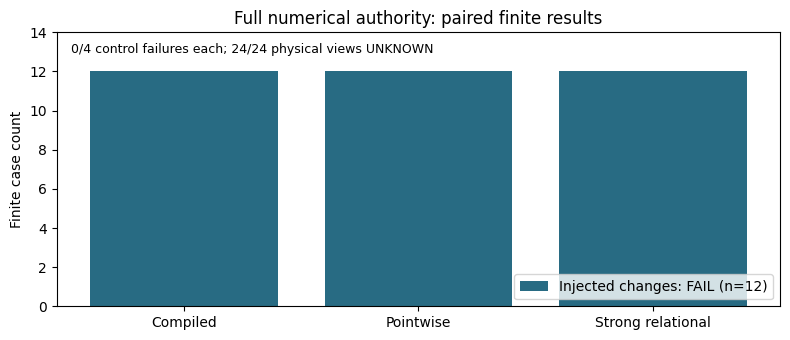

VERIFIED_SAVED_TRACE_REPLAY


In [4]:
# Optional presentation only; the numerical replay uses no plotting dependency.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib unavailable; the verified tables remain complete.")
else:
    plt.rcParams["svg.hashsalt"] = RELEASE_ID
    fig, ax = plt.subplots(figsize=(8, 3.5))
    labels = ["Compiled", "Pointwise", "Strong relational"]
    ax.bar(labels, [12, 12, 12], color="#286b83", label="Injected changes: FAIL (n=12)")
    ax.set(ylim=(0, 14), ylabel="Finite case count",
           title="Full numerical authority: paired finite results")
    caption = "0/4 control failures each; 24/24 physical views UNKNOWN"
    ax.text(0.02, 0.96, caption,
            transform=ax.transAxes, va="top", fontsize=9)
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(working / "outcomes.svg", metadata={"Date": None})
    plt.show()
    plt.close(fig)
inventory = {p.relative_to(working).as_posix(): p for p in working.rglob("*") if p.is_file()}
export_names = expected_names - {"replay-report.json"}
platform_names = {"__notebook__.ipynb"}
assert not set(inventory) - export_names - platform_names - {"replay-report.json"}
files = {name: hashlib.sha256(inventory[name].read_bytes()).hexdigest()
         for name in sorted(set(inventory) & export_names)}
platform = {name: hashlib.sha256(inventory[name].read_bytes()).hexdigest()
            for name in sorted(set(inventory) & platform_names)}
report = {"schema_version": 1, "release_id": RELEASE_ID, "payload_sha256": PAYLOAD_SHA256,
          "payload_manifest_sha256": PAYLOAD_MANIFEST_SHA256, "input_representation": representation,
          "platform_runtime_files_not_exported": platform,
          "status": "VERIFIED_SAVED_TRACE_REPLAY", "files": files}
(working / "replay-report.json").write_text(
    json.dumps(report, indent=2) + "\n", encoding="utf-8", newline="\n")
print(report["status"])


Original contributions: Apache-2.0; retained publisher licenses and
explicit derivative/redaction notices are in the dataset.
AI tools were used for research planning and experimental design; code preparation
and testing; data analysis and interpretation; figure preparation; and manuscript
drafting, revision, and review. The human author(s) retain responsibility for the
final work. The automated checks and AI-assisted reviews reported here are not
independent human peer review. Recorded tools include OpenAI Codex/ChatGPT;
exact model identifiers were not consistently recorded.
The dataset also provides manuscript.pdf and versioned source/supplement
archives. The notebook executes saved-output analysis, not those full archives.
Cite `abdullah2hamza/boundary-conformance-replay`, its Kaggle
version, release ID and payload SHA256. No peer-review acceptance or DOI
is asserted. See `README.md` and `THIRD_PARTY_NOTICES.md` in the dataset.
